In [ ]:
pacman::p_load(dplyr,ggplot2,tidyr,stringr)

args <- commandArgs(trailingOnly = TRUE)

taxonomy_abundances="../../2026-07_new_tax_clustering/taxonomy_linking_prefilter_TPM_0/merged_salmon_abund_transcript_names_tax.tsv"
taxonomy_name_links="../../2026-07_new_tax_clustering/taxonomy_linking_prefilter_TPM_0/merged_salmon_abund_transcript_names__.tsv"
output_file="test.csv"
nutrient_data_1="/users/akrinos/data/arianna/2025-provincetown-metaT/environmental_data/CC_wet_chemistry_2000_2021.csv"
nutrient_data_2="/users/akrinos/data/arianna/2025-provincetown-metaT/environmental_data/CC_wet_chemistry_2022_2023.csv"

## read in taxonomy linked to abundances
merged_w_tax = read.csv(taxonomy_abundances) %>%
    dplyr::filter(E.value<0.00001)

## separate into taxonomic labels
merged_w_tax = merged_w_tax %>%
    tidyr::separate(full_classification,sep=";",into=c("Domain","Supergroup","Phylum",
                                                       "Class","Order","Family",
                                                       "Genus","Species"))

tax_abundances = read.csv(taxonomy_name_links)

## read in environmental phosphate abundances
phos_ptown = read.csv(nutrient_data_1) %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv(nutrient_data_2) %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))

phos_ptown_dt = phos_ptown%>% dplyr::filter(PARAM_CODE=="PO4") %>% 
    dplyr::filter(DEPTH<5)
phos_ptown_dt = phos_ptown_dt %>% dplyr::group_by(Date,STAT_ID) %>%
    dplyr::summarize(phosphate = mean(FFU_RESULT))%>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                 format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))


## read in environmental nitrate/nitrite/ammonium abundances
nitr_ptown = read.csv(nutrient_data_1) %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv(nutrient_data_2) %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))
nitr_ptown_dt = nitr_ptown%>% dplyr::filter(DEPTH<5)

nitr_ptown_dt = nitr_ptown_dt %>% dplyr::filter(PARAM_CODE %in% 
                                             c("NO2","NO3","NO3+NO2")) %>%
    dplyr::group_by(PARAM_CODE,STAT_ARRIV,STAT_ID,Date) %>%
    dplyr::summarize(FFU_RESULT = mean(FFU_RESULT,na.rm=TRUE)) %>%
    pivot_wider(id_cols = c("STAT_ARRIV","STAT_ID","Date"),names_from="PARAM_CODE",
                values_from="FFU_RESULT")

nitr_ptown_dt = nitr_ptown_dt %>% 
    dplyr::rename(c("NO3_NO2"="NO3+NO2")) %>%
    dplyr::mutate(nitrate = case_when(is.na(NO3_NO2) ~ NO3+NO2,
                                      TRUE~NO3_NO2))%>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))

ammon_ptown = read.csv(nutrient_data_1) %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv(nutrient_data_2) %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))
ammon_ptown_dt = ammon_ptown %>% dplyr::filter(DEPTH<5)

ammon_ptown_dt = ammon_ptown_dt %>% dplyr::filter(PARAM_CODE %in% 
                                             c("NH4")) %>%
    dplyr::group_by(PARAM_CODE,STAT_ARRIV,STAT_ID,Date) %>%
    dplyr::summarize(FFU_RESULT = mean(FFU_RESULT,na.rm=TRUE)) %>%
    pivot_wider(id_cols = c("STAT_ARRIV","STAT_ID","Date"),names_from="PARAM_CODE",
                values_from="FFU_RESULT")

ammon_ptown_dt = ammon_ptown_dt %>% 
    dplyr::rename(c("ammonium"="NH4")) %>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                 format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))


## filter taxa that pass threshold of presence of all 4 KOs
pass_threshold = merged_w_tax %>% dplyr::mutate(Order=trimws(Order)) %>%
    dplyr::filter(trimws(Phylum)%in%c("Ochrophyta","Dinoflagellata",
                                      "Haptophyta","Chlorophyta",
                                      "Rhodophyta","Cryptophyta"))%>%
    dplyr::group_by(Order) %>%
    dplyr::summarize(KO_merged=paste(sort(unique(KO)),collapse="|"),
                     num_KOs=length(unique(KO))) %>%
    dplyr::arrange(desc(num_KOs)) %>%
    dplyr::filter(num_KOs!=1) %>%
    dplyr::filter((grepl("K14430",KO_merged)&grepl("K14683",KO_merged))|
                  (grepl("K10534",KO_merged)&grepl("K02575",KO_merged))) %>%
    dplyr::filter(!is.na(Order)&!
                  (Order%in%c("Cyclotrichiida","Acanthoecida","Pedinellales",
                              "Flavobacteriales","Stramenopiles_XXX",
                              "Pinguiochrysidaceae")))

## filter based on whether at least 30 samples have reported abundances
## for the N genes to be used, the pair must be used in >30 samples.
passing_orders_n = merged_w_tax %>%
    dplyr::mutate(Order=trimws(Order)) %>% dplyr::group_by(Order,KO,Sample)%>%
    dplyr::summarize(TPM = sum(V4)) %>%
    tidyr::separate(Sample,sep="_",into=c("SampleNum","Rep",
                                  "Station","Year","Month"),
            remove=FALSE) %>%
    dplyr::mutate(transporter_annot=KO)%>%
    dplyr::mutate(Month = str_replace_all(Month, "SEPT", "SEP")) %>%
    dplyr::mutate(SampleDate=as.POSIXct(strptime(tolower(paste0(Year,"-",Month,"-01")),
                                                 format="%Y-%b-%d"))) %>%
    dplyr::left_join(ammon_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::left_join(nitr_ptown_dt,by=c("Station"="STAT_ID","SampleDate"))  %>%
    dplyr::filter((transporter_annot %in% c("K02575","K10534")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K10534"~
                                                 "low_affinity",
                                                 transporter_annot=="K02575"~
                                                 "high_affinity")) %>%
    dplyr::mutate(propTPM=TPM) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","nitrate"),
                                  names_from="transporter_interp",
                                             values_from="propTPM") %>%
    dplyr::filter(!is.na(low_affinity)&!is.na(high_affinity)) %>%
    dplyr::group_by(Order) %>% dplyr::tally() %>% dplyr::filter(n>30)

## summarize by transporter and Order
summarized_transporter = merged_w_tax %>%
    dplyr::mutate(Order=trimws(Order),Phylum=trimws(Phylum)) %>%
    dplyr::group_by(Order,Phylum,KO,Sample)%>%
    dplyr::summarize(TPM = sum(V4)) %>%
    tidyr::separate(Sample,sep="_",into=c("SampleNum","Rep","Station","Year","Month"),
                    remove=FALSE) %>%
    dplyr::mutate(transporter_annot=KO)%>%
    dplyr::mutate(Month = str_replace_all(Month, "SEPT", "SEP")) %>%
    dplyr::mutate(SampleDate=as.POSIXct(strptime(tolower(paste0(Year,"-",Month,"-01")),
                                                 format="%Y-%b-%d"))) %>%
    dplyr::filter((Order%in%pass_threshold$Order)&(Order%in%passing_orders_n$Order))

for_calculation = summarized_transporter %>%
    dplyr::left_join(ammon_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::left_join(nitr_ptown_dt,by=c("Station"="STAT_ID","SampleDate"))  %>%
    dplyr::filter((transporter_annot %in% c("K10534","K02575")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K10534"~"low_affinity",
                                                 transporter_annot=="K02575"~"high_affinity")) %>%
    dplyr::group_by(Station,Order,SampleDate,nitrate,ammonium,Sample,transporter_interp) %>%
    dplyr::mutate(propTPM=TPM) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","nitrate","ammonium"),
                       names_from="transporter_interp",
                       values_from="propTPM") %>%
    dplyr::mutate(low_affinity=case_when(is.na(low_affinity)~0,
                                         TRUE~low_affinity),
                  high_affinity=case_when(is.na(high_affinity)~0,
                                         TRUE~high_affinity)) %>%
    dplyr::group_by(Order) %>%
    dplyr::mutate(low_to_high = (high_affinity-low_affinity)/(low_affinity+high_affinity)) %>%
    dplyr::group_by(Order,nitrate,ammonium,Station,SampleDate,Sample) %>%
    dplyr::summarize(low_to_high=mean(low_to_high))

stats_frame = data.frame()
for_paper_stats_frame_n = data.frame()
for (order_curr in unique(for_calculation$Order)) {
    subset_fr = for_calculation %>% dplyr::filter(Order==order_curr) %>%
        dplyr::filter(!is.na(ammonium)&!is.na(low_to_high)&!is.na(nitrate)) %>%
        dplyr::mutate(summed_n = ammonium + nitrate)
    print(order_curr)
    spearman_corr = cor.test(subset_fr$summed_n,subset_fr$low_to_high,method="spearman")
    print(spearman_corr)
    linear_res = lm(subset_fr$low_to_high~log10(subset_fr$summed_n))
    linear_res = lm(subset_fr$low_to_high~log10(subset_fr$summed_n))
    print(summary(linear_res))
    
    print(as.numeric(predict(linear_res)))
    min_y_pred <- min(predict(linear_res))
    max_y_pred <- max(predict(linear_res))
    max_y = max(subset_fr$low_to_high)
    min_y = min(subset_fr$low_to_high)
    half_decay_y <- -0.5#0.5#0.5#(min_y+max_y)/2 #0.5#(min_y+max_y)/2 #(min_y_pred) / 2 # y value at 1/2 of the max.
    intercept <- as.numeric(coef(linear_res)[1])
    slope <- as.numeric(coef(linear_res)[2])
    print(half_decay_y)
    print(intercept)
    print(slope)
    log10_x_at_half_decay <- (half_decay_y - intercept) / slope
    print(log10_x_at_half_decay)
    
    x_at_half_decay <- 10^(log10_x_at_half_decay)
    
    print(paste0("x intercept is ",-linear_res$coefficients[1]/linear_res$coefficients[2]))
    stats_frame = stats_frame %>%
        dplyr::bind_rows(data.frame("Taxon"=order_curr,
                                    "X_intercept"=10^(-linear_res$coefficients[1]/linear_res$coefficients[2]),
                                    "half_decay_y"=half_decay_y,
                                    "x_at_half_decay"=x_at_half_decay,
                                    "linear_R_square"=summary(linear_res)$r.squared,
                                    "linear_p_val"=summary(linear_res)$coefficients[,4][2],
                                    "linear_slope"=linear_res$coefficients[2],
                                    "linear_intercept"=linear_res$coefficients[1],
                                    "spearman_corr" = spearman_corr$estimate,
                                    "spearman_p_val" = spearman_corr$p.value))
    
    
    for_paper_stats_frame_n = for_paper_stats_frame_n %>%
        dplyr::bind_rows(data.frame("Taxon"=order_curr,
                                    "estimated_parameter"=x_at_half_decay,
                                    "exponential_slope"=linear_res$coefficients[2],
                                    "exponential_intercept"=linear_res$coefficients[1],
                                    "exponential_p_val"=summary(linear_res)$coefficients[,4][2],
                                    "exponential_R_square"=summary(linear_res)$r.squared,
                                    "spearman_corr" = spearman_corr$estimate,
                                    "spearman_p_val" = spearman_corr$p.value))
                                    
}

write.csv(for_paper_stats_frame_n  %>% dplyr::filter(exponential_p_val < 0.15) ,output_file)


Warning message:
“Expected 8 pieces. Missing pieces filled with `NA` in 135399 rows [1, 2, 3, 4,
5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, ...].”


In [ ]:
for_paper_stats_frame_n  %>% dplyr::filter(exponential_p_val < 0.11)

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, summed_n, Station, SampleDate, and
  Sample.
ℹ Output is grouped by Order, summed_n, Station, and SampleDate.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, summed_n, Station, SampleDate, Sample))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
Warning message:
“Removed 636 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 6 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 636 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 6 rows containing missing values or values outside the scale range
(`geom_line()`).”


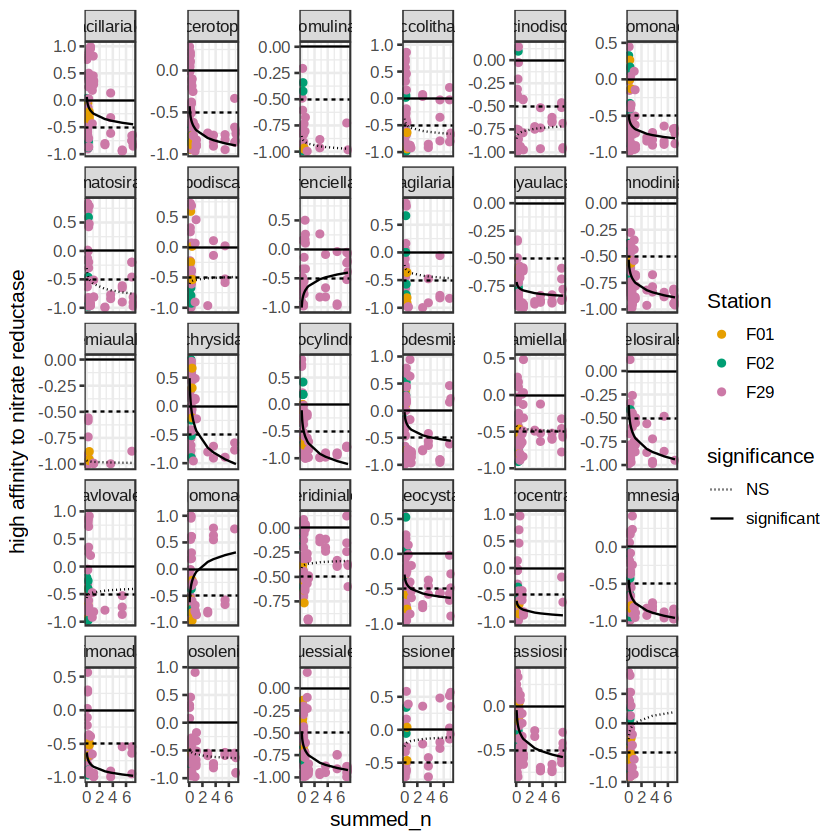

In [11]:
ggplot(summarized_transporter %>%
    dplyr::left_join(ammon_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::left_join(nitr_ptown_dt,by=c("Station"="STAT_ID","SampleDate"))  %>%
    dplyr::mutate(summed_n=nitrate+ammonium) %>%
    dplyr::filter((transporter_annot %in% c("K10534","K02575")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K10534"~"low_affinity",
                                                 transporter_annot=="K02575"~"high_affinity")) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","summed_n"),
                       names_from="transporter_interp",
                       values_from="TPM") %>%
    dplyr::group_by(Order) %>%
    dplyr::mutate(low_to_high = (high_affinity-low_affinity)/(low_affinity+high_affinity)) %>%
    dplyr::group_by(Order,summed_n,Station,SampleDate,Sample) %>%
    dplyr::summarize(low_to_high=mean(low_to_high)) %>%
    dplyr::left_join(stats_frame,by=c("Order"="Taxon")) %>%
    dplyr::mutate(modeled_value = linear_intercept + linear_slope*log10(summed_n)) %>%
    dplyr::mutate(significance=case_when(linear_p_val<0.11~"significant",
                                         TRUE ~ "NS"))) +
    geom_point(aes(x=summed_n,color=Station,y=low_to_high)) +
    geom_line(aes(x=summed_n,y=modeled_value,linetype=significance)) +
    scale_linetype_manual(values=c("dotted","solid"),
                          breaks=c("NS","significant")) + 
    scale_color_manual(values=c("#E69F00","#009E73","#CC79A7"),
                       breaks=c("F01","F02","F29")) + 
    geom_hline(aes(yintercept=0)) + 
    geom_hline(aes(yintercept=-0.5),linetype="dashed") + 
    theme_bw(base_size=12) + 
    facet_wrap(~Order,scales="free_y") + ylab("high affinity to nitrate reductase") 

ggsave("../figures/nitrogen_transporter_affinity.pdf",width=12,height=8,units="in")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, summed_n, Station, SampleDate, and
  Sample.
ℹ Output is grouped by Order, summed_n, Station, and SampleDate.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, summed_n, Station, SampleDate, Sample))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
Warning message:
“Removed 33 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 8 rows containing missing values or values outside the scale range
(`geom_line()`).”


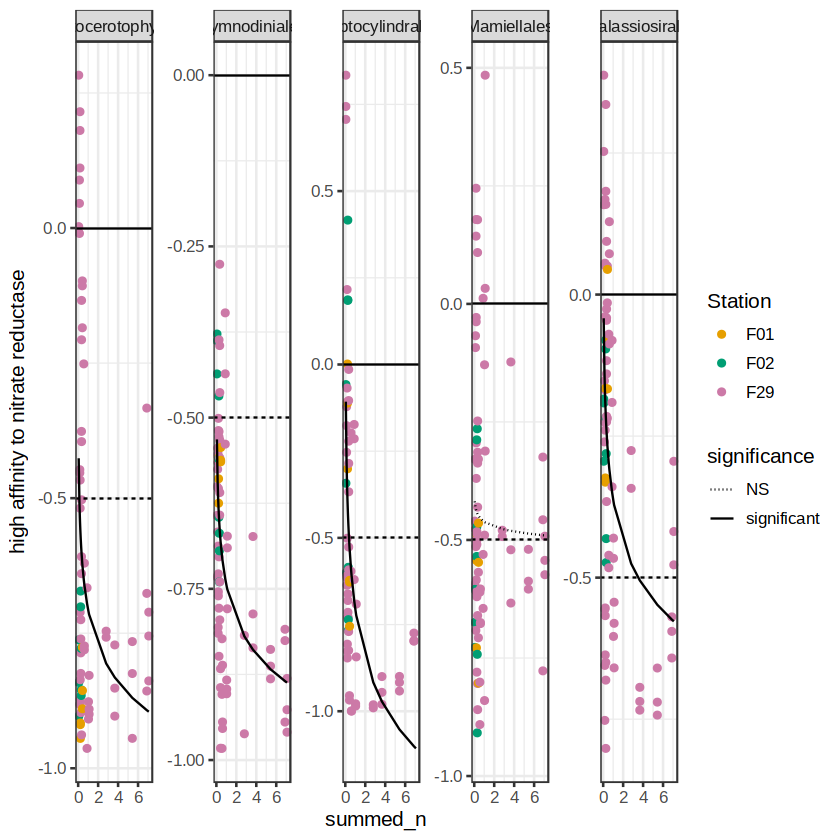

In [12]:
n_mini = ggplot(summarized_transporter %>%
    dplyr::left_join(ammon_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::left_join(nitr_ptown_dt,by=c("Station"="STAT_ID","SampleDate"))  %>%
    dplyr::mutate(summed_n=nitrate+ammonium) %>%
    dplyr::filter(Order%in%c("Chaetocerotophycidae","Gymnodiniales",
                             "Leptocylindrales","Mamiellales","Thalassiosirales")) %>%
    dplyr::filter((transporter_annot %in% c("K10534","K02575")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K10534"~"low_affinity",
                                                 transporter_annot=="K02575"~"high_affinity")) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","summed_n"),
                       names_from="transporter_interp",
                       values_from="TPM") %>%
    dplyr::group_by(Order) %>%
    dplyr::mutate(low_to_high = (high_affinity-low_affinity)/(low_affinity+high_affinity)) %>%
    dplyr::group_by(Order,summed_n,Station,SampleDate,Sample) %>%
    dplyr::summarize(low_to_high=mean(low_to_high)) %>%
    dplyr::left_join(stats_frame,by=c("Order"="Taxon")) %>%
    dplyr::mutate(modeled_value = linear_intercept + linear_slope*log10(summed_n)) %>%
    dplyr::mutate(significance=case_when(linear_p_val<0.11~"significant",
                                         TRUE ~ "NS"))) +
    geom_point(aes(x=summed_n,color=Station,y=low_to_high)) +
    geom_line(aes(x=summed_n,y=modeled_value,linetype=significance)) +
    scale_linetype_manual(values=c("dotted","solid"),
                          breaks=c("NS","significant")) + 
    scale_color_manual(values=c("#E69F00","#009E73","#CC79A7"),
                       breaks=c("F01","F02","F29")) + 
    geom_hline(aes(yintercept=0)) + 
    geom_hline(aes(yintercept=-0.5),linetype="dashed") + 
    theme_bw(base_size=12) + 
    facet_wrap(~Order,scales="free_y",nrow=1) + ylab("high affinity to nitrate reductase") 

#ggsave("../figures/phosphate_transporter_affinity.pdf",width=8,height=6,units="in")
n_mini

In [5]:

## read in taxonomy linked to abundances
merged_w_tax = read.csv(taxonomy_abundances) %>%
    dplyr::filter(E.value<0.00001)

## separate into taxonomic labels
merged_w_tax = merged_w_tax %>%
    tidyr::separate(full_classification,sep=";",into=c("Domain","Supergroup","Phylum",
                                                       "Class","Order","Family",
                                                       "Genus","Species"))

tax_abundances = read.csv(taxonomy_name_links)

## read in environmental phosphate abundances
phos_ptown = read.csv(nutrient_data_1) %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv(nutrient_data_2) %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))

phos_ptown_dt = phos_ptown%>% dplyr::filter(PARAM_CODE=="PO4") %>% 
    dplyr::filter(DEPTH<5)
phos_ptown_dt = phos_ptown_dt %>% dplyr::group_by(Date,STAT_ID) %>%
    dplyr::summarize(phosphate = mean(FFU_RESULT))%>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                 format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))


## read in environmental nitrate/nitrite/ammonium abundances
nitr_ptown = read.csv(nutrient_data_1) %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv(nutrient_data_2) %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))
nitr_ptown_dt = nitr_ptown%>% dplyr::filter(DEPTH<5)

nitr_ptown_dt = nitr_ptown_dt %>% dplyr::filter(PARAM_CODE %in% 
                                             c("NO2","NO3","NO3+NO2")) %>%
    dplyr::group_by(PARAM_CODE,STAT_ARRIV,STAT_ID,Date) %>%
    dplyr::summarize(FFU_RESULT = mean(FFU_RESULT,na.rm=TRUE)) %>%
    pivot_wider(id_cols = c("STAT_ARRIV","STAT_ID","Date"),names_from="PARAM_CODE",
                values_from="FFU_RESULT")

nitr_ptown_dt = nitr_ptown_dt %>% 
    dplyr::rename(c("NO3_NO2"="NO3+NO2")) %>%
    dplyr::mutate(nitrate = case_when(is.na(NO3_NO2) ~ NO3+NO2,
                                      TRUE~NO3_NO2))%>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))

ammon_ptown = read.csv(nutrient_data_1) %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv(nutrient_data_2) %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))
ammon_ptown_dt = ammon_ptown %>% dplyr::filter(DEPTH<5)

ammon_ptown_dt = ammon_ptown_dt %>% dplyr::filter(PARAM_CODE %in% 
                                             c("NH4")) %>%
    dplyr::group_by(PARAM_CODE,STAT_ARRIV,STAT_ID,Date) %>%
    dplyr::summarize(FFU_RESULT = mean(FFU_RESULT,na.rm=TRUE)) %>%
    pivot_wider(id_cols = c("STAT_ARRIV","STAT_ID","Date"),names_from="PARAM_CODE",
                values_from="FFU_RESULT")

ammon_ptown_dt = ammon_ptown_dt %>% 
    dplyr::rename(c("ammonium"="NH4")) %>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                 format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))


## filter taxa that pass threshold of presence of all 4 KOs
pass_threshold = merged_w_tax %>% dplyr::mutate(Order=trimws(Order)) %>%
    dplyr::filter(trimws(Phylum)%in%c("Ochrophyta","Dinoflagellata",
                                      "Haptophyta","Chlorophyta",
                                      "Rhodophyta","Cryptophyta"))%>%
    dplyr::group_by(Order) %>%
    dplyr::summarize(KO_merged=paste(sort(unique(KO)),collapse="|"),
                     num_KOs=length(unique(KO))) %>%
    dplyr::arrange(desc(num_KOs)) %>%
    dplyr::filter(num_KOs!=1) %>%
    dplyr::filter((grepl("K14430",KO_merged)&grepl("K14683",KO_merged))|
                  (grepl("K10534",KO_merged)&grepl("K02575",KO_merged))) %>%
    dplyr::filter(!is.na(Order)&!
                  (Order%in%c("Cyclotrichiida","Acanthoecida","Pedinellales",
                              "Flavobacteriales","Stramenopiles_XXX",
                              "Pinguiochrysidaceae")))

## filter based on whether at least 30 samples have reported abundances

passing_orders = merged_w_tax %>%
    dplyr::mutate(Order=trimws(Order)) %>% dplyr::group_by(Order,KO,Sample)%>%
    dplyr::summarize(TPM = sum(V4)) %>%
    tidyr::separate(Sample,sep="_",into=c("SampleNum","Rep","Station","Year","Month"),remove=FALSE) %>%
    dplyr::mutate(transporter_annot=KO)%>%
    dplyr::mutate(Month = str_replace_all(Month, "SEPT", "SEP")) %>%
    dplyr::mutate(SampleDate=as.POSIXct(strptime(tolower(paste0(Year,"-",Month,"-01")),
                                                 format="%Y-%b-%d"))) %>%
    dplyr::left_join(phos_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::filter((transporter_annot %in% c("K14430","K14683")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K14430"~"low_affinity",
                                                 transporter_annot=="K14683"~"high_affinity")) %>%
    dplyr::mutate(propTPM=TPM) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","phosphate"),
                       names_from="transporter_interp",
                       values_from="propTPM") %>%
    dplyr::filter(!is.na(low_affinity)&!is.na(high_affinity)) %>%
    dplyr::group_by(Order) %>% dplyr::tally() %>% dplyr::filter(n>30)

## summarize by transporter and Order
summarized_transporter = merged_w_tax %>%
    dplyr::mutate(Order=trimws(Order),Phylum=trimws(Phylum)) %>% dplyr::group_by(Order,Phylum,KO,Sample)%>%
    dplyr::summarize(TPM = sum(V4)) %>%
    tidyr::separate(Sample,sep="_",into=c("SampleNum","Rep","Station","Year","Month"),remove=FALSE) %>%
    dplyr::mutate(transporter_annot=KO)%>%
    dplyr::mutate(Month = str_replace_all(Month, "SEPT", "SEP")) %>%
    dplyr::mutate(SampleDate=as.POSIXct(strptime(tolower(paste0(Year,"-",Month,"-01")),
                                                 format="%Y-%b-%d"))) %>%
    dplyr::filter((Order%in%pass_threshold$Order)&(Order%in%passing_orders$Order))

for_calculation = summarized_transporter %>%
    dplyr::left_join(phos_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::filter((transporter_annot %in% c("K14430","K14683")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K14430"~"low_affinity",
                                                 transporter_annot=="K14683"~"high_affinity")) %>%
    dplyr::mutate(propTPM=TPM) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","phosphate"),
                       names_from="transporter_interp",
                       values_from="propTPM") %>%
    dplyr::mutate(low_affinity=case_when(is.na(low_affinity)~0,
                                         TRUE~low_affinity),
                  high_affinity=case_when(is.na(high_affinity)~0,
                                         TRUE~high_affinity)) %>%
    dplyr::group_by(Order) %>%
    dplyr::mutate(low_to_high = (high_affinity-low_affinity)/(low_affinity+high_affinity)) %>%
    dplyr::group_by(Order,phosphate,Station,SampleDate,Sample) %>%
    dplyr::summarize(low_to_high=mean(low_to_high))

stats_frame = data.frame()
for_paper_stats_frame = data.frame()
for (order_curr in unique(for_calculation$Order)) {
    subset_fr = for_calculation %>% dplyr::filter(Order==order_curr) %>%
        dplyr::filter(!is.na(phosphate)&!is.na(low_to_high)) %>%
        dplyr::mutate(phosphate = phosphate + 0.001)
    print(order_curr)
    spearman_corr = cor.test(subset_fr$phosphate,subset_fr$low_to_high,method="spearman")
    print(spearman_corr)
    linear_res = lm(subset_fr$low_to_high~log10(subset_fr$phosphate))
    linear_res = lm(subset_fr$low_to_high~subset_fr$phosphate)
    print(summary(linear_res))
    
    print(as.numeric(predict(linear_res)))
    min_y_pred <- min(predict(linear_res))
    max_y_pred <- max(predict(linear_res))
    max_y = max(subset_fr$low_to_high)
    min_y = min(subset_fr$low_to_high)
    half_decay_y <- 0#0.5#0.5#(min_y+max_y)/2 #0.5#(min_y+max_y)/2 #(min_y_pred) / 2 # y value at 1/2 of the max.
    intercept <- as.numeric(coef(linear_res)[1])
    slope <- as.numeric(coef(linear_res)[2])
    print(half_decay_y)
    print(intercept)
    print(slope)
    log10_x_at_half_decay <- (half_decay_y - intercept) / slope
    print(log10_x_at_half_decay)
    
    x_at_half_decay <- log10_x_at_half_decay#10^(log10_x_at_half_decay)
    
    print(paste0("x intercept is ",-linear_res$coefficients[1]/linear_res$coefficients[2]))
    stats_frame = stats_frame %>%
        dplyr::bind_rows(data.frame("Taxon"=order_curr,
                                    "X_intercept"=10^(-linear_res$coefficients[1]/linear_res$coefficients[2]),
                                    "half_decay_y"=half_decay_y,
                                    "x_at_half_decay"=x_at_half_decay,
                                    "linear_R_square"=summary(linear_res)$r.squared,
                                    "linear_p_val"=summary(linear_res)$coefficients[,4][2],
                                    "linear_slope"=linear_res$coefficients[2],
                                    "linear_intercept"=linear_res$coefficients[1],
                                    "spearman_corr" = spearman_corr$estimate,
                                    "spearman_p_val" = spearman_corr$p.value))
    
    
    for_paper_stats_frame = for_paper_stats_frame %>%
        dplyr::bind_rows(data.frame("Taxon"=order_curr,
                                    "estimated_parameter"=x_at_half_decay,
                                    "exponential_slope"=linear_res$coefficients[2],
                                    "exponential_intercept"=linear_res$coefficients[1],
                                    "exponential_p_val"=summary(linear_res)$coefficients[,4][2],
                                    "exponential_R_square"=summary(linear_res)$r.squared,
                                    "spearman_corr" = spearman_corr$estimate,
                                    "spearman_p_val" = spearman_corr$p.value))
                                    
}


Warning message:
“Expected 8 pieces. Missing pieces filled with `NA` in 135399 rows [1, 2, 3, 4,
5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, ...].”
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date and STAT_ID.
ℹ Output is grouped by Date.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, STAT_ID))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by PARAM_CODE, STAT_ARRIV, STAT_ID, and Date.
ℹ Output is grouped by PARAM_CODE, STAT_ARRIV, and STAT_ID.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(PARAM_CODE, STAT_ARRIV, STAT_ID, Date))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by PARAM_CODE, STAT_ARRIV, STAT_ID, and Date.
ℹ Output is grouped by PARAM_CODE, STAT_ARRIV, and STAT

[1] "Bacillariales"


Warning message in cor.test.default(subset_fr$phosphate, subset_fr$low_to_high, :
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  subset_fr$phosphate and subset_fr$low_to_high
S = 83058, p-value = 0.04865
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
-0.2300354 



Warning message in eval(predvars, data, env):
“NaNs produced”


...


Call:
lm(formula = subset_fr$low_to_high ~ subset_fr$phosphate)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.71581 -0.10113  0.07058  0.13476  0.19778 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)          0.80502    0.03431  23.463   <2e-16 ***
subset_fr$phosphate  0.31044    0.12314   2.521   0.0138 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.2075 on 75 degrees of freedom
Multiple R-squared:  0.07812,	Adjusted R-squared:  0.06583 
F-statistic: 6.356 on 1 and 75 DF,  p-value: 0.01383

 [1] 0.8022216 0.8022216 0.8022216 0.8093617 0.8093617 0.8093617 0.8112243
 [8] 0.8112243 0.8112243 0.8118452 0.8118452 0.8118452 0.8127765 0.8127765
[15] 0.8127765 0.8180540 0.8255045 0.8255045 0.8255045 0.8258149 0.8258149
[22] 0.8258149 0.8289193 0.8289193 0.8289193 0.8335759 0.8335759 0.8335759
[29] 0.8357490 0.8357490 0.8357490 0.8391638 0.8391638 0.8391638 0.8419578
[36] 0.8419578 0.84

Warning message in cor.test.default(subset_fr$phosphate, subset_fr$low_to_high, :
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  subset_fr$phosphate and subset_fr$low_to_high
S = 138975, p-value = 4.199e-10
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
-0.6288681 



Warning message in eval(predvars, data, env):
“NaNs produced”



Call:
lm(formula = subset_fr$low_to_high ~ subset_fr$phosphate)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.58103 -0.15480  0.00437  0.18839  0.48003 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)          0.71822    0.03498  20.531  < 2e-16 ***
subset_fr$phosphate -1.11275    0.12344  -9.014 1.01e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.2175 on 78 degrees of freedom
Multiple R-squared:  0.5102,	Adjusted R-squared:  0.5039 
F-statistic: 81.26 on 1 and 78 DF,  p-value: 1.012e-13

 [1]  0.72823107  0.72823107  0.72823107  0.70263787  0.70263787  0.70263787
 [7]  0.69596139  0.69596139  0.69596139  0.69373589  0.69373589  0.69373589
[13]  0.69039765  0.69039765  0.69039765  0.67148094  0.67148094  0.67148094
[19]  0.64477499  0.64477499  0.64477499  0.64366224  0.64366224  0.64366224
[25]  0.63253477  0.63253477  0.63253477  0.61584355  0.61584355  0.61584355
[31]  0.6

In [7]:
phosphate_small = ggplot(summarized_transporter %>%
    dplyr::left_join(phos_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::filter((transporter_annot %in% c("K14430","K14683")))%>%
    dplyr::filter(Order%in%c("Chaetocerotophycidae","Gymnodiniales",
                             "Leptocylindrales","Mamiellales","Thalassiosirales")) %>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K14430"~"low_affinity",
                                                 transporter_annot=="K14683"~"high_affinity")) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","phosphate"),
                       names_from="transporter_interp",
                       values_from="TPM") %>%
    dplyr::group_by(Order) %>%
    dplyr::mutate(low_to_high = (high_affinity-low_affinity)/(low_affinity+high_affinity)) %>%
    dplyr::group_by(Order,phosphate,Station,SampleDate,Sample) %>%
    dplyr::summarize(low_to_high=mean(low_to_high)) %>%
    dplyr::left_join(stats_frame,by=c("Order"="Taxon")) %>%
    dplyr::mutate(modeled_value = linear_intercept + linear_slope*phosphate) %>%
    dplyr::mutate(significance=case_when(linear_p_val<0.11~"significant",
                                         TRUE ~ "NS"))) +
    geom_point(aes(x=phosphate,color=Station,y=low_to_high)) +
    geom_line(aes(x=phosphate,y=modeled_value,linetype=significance)) +
    scale_linetype_manual(values=c("dotted","solid"),
                          breaks=c("NS","significant")) + 
    scale_color_manual(values=c("#E69F00","#009E73","#CC79A7"),
                       breaks=c("F01","F02","F29")) + 
    geom_hline(aes(yintercept=0)) + 
    theme_bw(base_size=12) + 
    facet_wrap(~Order,scales="free_y",nrow=1) + ylab("high affinity to low affinity") 

ggsave("../figures/phosphate_transporter_linear_small.png",plot=phosphate_small,width=8,height=6,units="in")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, phosphate, Station, SampleDate, and
  Sample.
ℹ Output is grouped by Order, phosphate, Station, and SampleDate.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, phosphate, Station, SampleDate, Sample))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
Warning message:
“Removed 46 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_line()`).”


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, phosphate, Station, SampleDate, and
  Sample.
ℹ Output is grouped by Order, phosphate, Station, and SampleDate.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, phosphate, Station, SampleDate, Sample))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
Warning message:
“Removed 340 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 7 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 340 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 7 rows containing missing values or values outside the scale range
(`geom_line()`).”


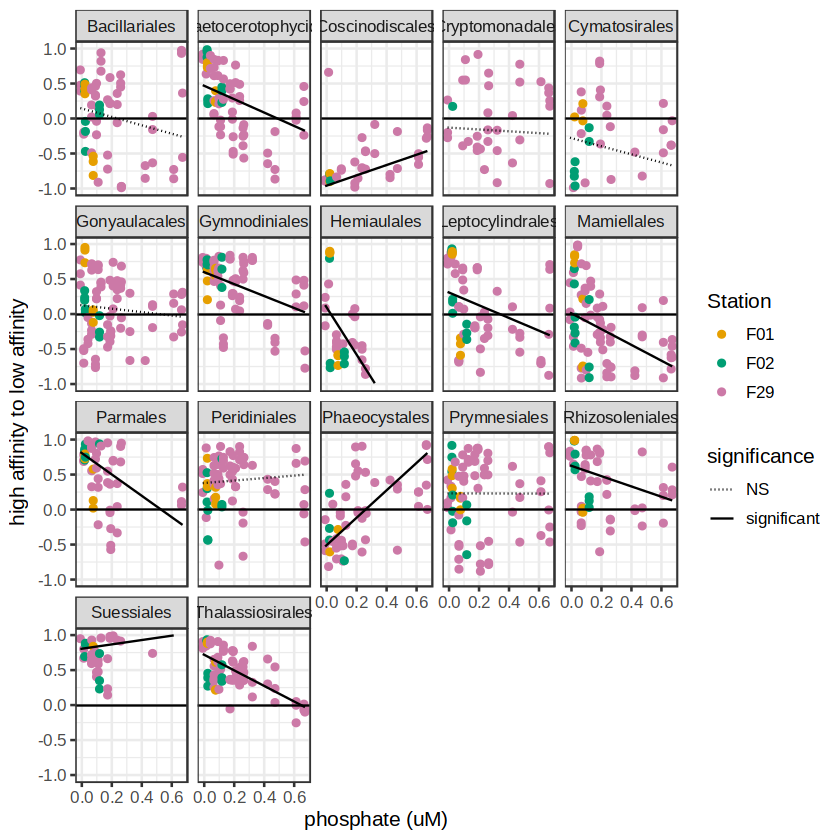

In [8]:
ggplot(summarized_transporter %>%
    dplyr::left_join(phos_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::filter((transporter_annot %in% c("K14430","K14683")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K14430"~"low_affinity",
                                                 transporter_annot=="K14683"~"high_affinity")) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","phosphate"),
                       names_from="transporter_interp",
                       values_from="TPM") %>%
    dplyr::group_by(Order) %>%
    dplyr::mutate(low_to_high = (high_affinity-low_affinity)/(low_affinity+high_affinity)) %>%
    dplyr::group_by(Order,phosphate,Station,SampleDate,Sample) %>%
    dplyr::summarize(low_to_high=mean(low_to_high)) %>%
    dplyr::left_join(stats_frame,by=c("Order"="Taxon")) %>%
    dplyr::mutate(modeled_value = linear_intercept + linear_slope*phosphate) %>%
    dplyr::mutate(significance=case_when(linear_p_val<0.11~"significant",
                                         TRUE ~ "NS"))) +
    geom_point(aes(x=phosphate,color=Station,y=low_to_high)) +
    geom_line(aes(x=phosphate,y=modeled_value,linetype=significance)) +
    scale_linetype_manual(values=c("dotted","solid"),
                          breaks=c("NS","significant")) + 
    geom_hline(aes(yintercept=0)) + xlab("phosphate (uM)") + 
    scale_color_manual(values=c("#E69F00","#009E73","#CC79A7"),
                       breaks=c("F01","F02","F29")) + 
    #geom_hline(aes(yintercept=0.5),linetype="dashed") + 
    theme_bw(base_size=12) + ylim(c(-1,1))+
    facet_wrap(~Order) + ylab("high affinity to low affinity") 

ggsave("../figures/phosphate_transporter_linear.pdf",width=10,height=8,units="in")

In [13]:
predict_merge = (n_mini / phosphate_small) + plot_layout(guides = "collect")
ggsave("../figures/predict_diatom.png",plot=predict_merge,width=12,height=6,units="in")
ggsave("../figures/predict_diatom.pdf",plot=predict_merge,width=12,height=6,units="in")

ERROR: Error in n_mini/phosphate_small: non-numeric argument to binary operator
